# Degradación de la red viaria de Granada bajo lluvia (cuaderno mínimo)

Cuaderno de extremo a extremo con **un escenario** (*moderada*). Carga la red, importa la muestra de trayectos, la verifica y calcula el **factor de degradación** por trayecto (tiempo con lluvia / tiempo en seco). Toda la lógica vive en el módulo `trafico_lluvia`; aquí solo se narra y se muestra.

Ejecutar: `uv run jupyter nbconvert --to notebook --execute --inplace cuaderno_lluvia.ipynb`

In [1]:
from pathlib import Path

from trafico_lluvia import (
    ESCENARIOS, analizar, cargar_muestra, cargar_red,
    guardar_tablas, tabla_escenarios, verificar_muestra,
)

SALIDAS = Path("salidas")  # carpeta de salida única

## 1. La red

In [2]:
G = cargar_red()
km = sum(d.get("length", 0) for _, _, d in G.edges(data=True)) / 1000
print(f"Red de Granada: {len(G.nodes):,} nodos, {len(G.edges):,} aristas, {km:,.0f} km")

Red de Granada: 5,221 nodos, 10,243 aristas, 818 km


## 2. La muestra de trayectos

> **Es una muestra, no un modelo de la ciudad.** Son 16 pares periferia → centro (9 corredores más el par extra de Parking del Triunfo, destino Puerta Real, nodo `534921646`), elegidos para tener accesos representativos. Los resultados describen estos trayectos, no el tráfico de Granada en conjunto.

In [3]:
muestra = cargar_muestra(G)
verificar_muestra(G, muestra)  # falla con mensaje claro si falta ruta o los tiempos secos no coinciden con trayectos.csv (< 1 s)
print(f"Muestra verificada: {len(muestra)} pares, {muestra.corredor.nunique()} corredores; tiempos secos coinciden con trayectos.csv.")
muestra

Muestra verificada: 16 pares, 10 corredores; tiempos secos coinciden con trayectos.csv.


,corredor,origen,destino,tiempo_seco_csv_s
0,Camino de Ronda,4520478554,534921646,359.0
1,Camino de Ronda,4520478553,534921646,357.0
2,Av. de Andalucía,559691143,534921646,680.0
3,Av. de Andalucía,3435223168,534921646,677.0
4,Ctra. de Málaga,983525310,534921646,646.0
5,Ctra. de Málaga,7260359798,534921646,693.0
6,Ctra. de Murcia,1457605871,534921646,778.0
7,Ctra. de Murcia,1457605799,534921646,711.0
8,Ronda Sur,83301193,534921646,493.0
9,Ronda Sur,8090482736,534921646,484.0


## 3. Escenario *moderada*

Reducción de velocidad por clase de vía (fuente: ticket 02; para Granada es extrapolación).

In [4]:
escenario = ESCENARIOS["moderada"]
tabla_escenarios([escenario])

,escenario,intensidad_mm_h,reduccion_urbana,rango_urbana,reduccion_interurbana,rango_interurbana,confianza,fuente
0,moderada,"2,5 - 6,35",0.07,5% a 10%,0.06,4% a 10%,media,ticket 02


## 4. Degradación por trayecto

La ruta se **recalcula** con los tiempos degradados (cada arista se reescala por 1/(1−δ) según su clase de vía), no se reescala la ruta seca.

In [5]:
resultado = analizar(G, muestra, [escenario])
tabla = resultado.por_trayecto[
    ["corredor", "tiempo_seco_s", "tiempo_lluvia_s", "factor_degradacion", "ruta_cambia"]
].round({"tiempo_seco_s": 0, "tiempo_lluvia_s": 0, "factor_degradacion": 3})
tabla

,corredor,tiempo_seco_s,tiempo_lluvia_s,factor_degradacion,ruta_cambia
0,Camino de Ronda,359.0,386.0,1.075,False
1,Camino de Ronda,357.0,384.0,1.075,False
2,Av. de Andalucía,680.0,727.0,1.068,False
3,Av. de Andalucía,677.0,723.0,1.068,False
4,Ctra. de Málaga,646.0,690.0,1.068,False
5,Ctra. de Málaga,693.0,740.0,1.069,False
6,Ctra. de Murcia,778.0,837.0,1.075,False
7,Ctra. de Murcia,711.0,764.0,1.075,False
8,Ronda Sur,493.0,528.0,1.073,False
9,Ronda Sur,484.0,520.0,1.073,False


In [6]:
print(f"Factor de degradación: mín {tabla.factor_degradacion.min():.3f}, máx {tabla.factor_degradacion.max():.3f}; "
      f"trayectos que cambian de ruta: {int(tabla.ruta_cambia.sum())} de {len(tabla)}")
resultado.por_corredor

Factor de degradación: mín 1.068, máx 1.075; trayectos que cambian de ruta: 0 de 16


,escenario,corredor,factor_medio,factor_min,factor_max,trayectos
0,moderada,Camino de Ronda,1.075269,1.075269,1.075269,2
1,moderada,Av. de Andalucía,1.067974,1.067963,1.067985,2
2,moderada,Ctra. de Málaga,1.068421,1.068182,1.068660,2
3,moderada,Ctra. de Murcia,1.075269,1.075269,1.075269,2
4,moderada,Ronda Sur,1.072960,1.072883,1.073036,2
5,moderada,Ctra. de la Sierra,1.075269,1.075269,1.075269,1
6,moderada,Av. de Dílar,1.075269,1.075269,1.075269,2
7,moderada,Av. de Pulianas,1.075269,1.075269,1.075269,1
8,moderada,Camino de Alfacar,1.075269,1.075269,1.075269,1
9,moderada,Parking del Triunfo (Av. Constitución),1.075269,1.075269,1.075269,1


## 5. Límites (resumen)

Con un único factor de velocidad el modelo da un factor ≈ 1/(1−δ): **no reproduce el colapso** observado cerca de capacidad. Sin capacidad, semáforos, incidentes ni cambios de demanda. Los límites completos llegan en tickets posteriores.

In [7]:
guardar_tablas(resultado, SALIDAS)
sorted(p.name for p in SALIDAS.iterdir())

['degradacion_por_corredor.csv',
 'degradacion_por_trayecto.csv',
 'visor_trayectos.html']

# Escenarios completos, sensibilidad y degradación por corredor

Los cuatro escenarios (ligera, moderada, fuerte, torrencial) con valor central y rango. Las vías `motorway`/`trunk` (y sus enlaces) usan la reducción interurbana; el resto, la urbana (decisión de la spec). **El escenario *torrencial* es una extrapolación** (confianza muy baja): no hay datos de Granada y los de la bibliografía apenas cubren esas intensidades.

In [8]:
from trafico_lluvia.sensibilidad import (
    analizar_con_rango, cambios_de_ruta, curva_sensibilidad, figura_curva, figura_principal,
)

tabla_esc = tabla_escenarios(ESCENARIOS)
tabla_esc.to_csv(SALIDAS / "escenarios.csv", index=False)
tabla_esc

,escenario,intensidad_mm_h,reduccion_urbana,rango_urbana,reduccion_interurbana,rango_interurbana,confianza,fuente
0,ligera,"< 2,5",0.03,1% a 5%,0.03,2% a 5%,media,ticket 02
1,moderada,"2,5 - 6,35",0.07,5% a 10%,0.06,4% a 10%,media,ticket 02
2,fuerte,"6,35 - 30",0.11,7% a 20%,0.09,6% a 17%,baja,ticket 02
3,torrencial,> 30,0.22,15% a 35%,0.20,15% a 35%,muy baja (extrapolación),ticket 02


### Definición del agregado por corredor

- **Por trayecto:** factor = tiempo con lluvia (ruta recalculada) / tiempo seco, con la reducción central; `factor_minimo` y `factor_maximo` usan los extremos del rango.
- **Por corredor:** `factor_medio` es la **media aritmética** del factor central de sus trayectos; la banda (`banda_min`, `banda_max`) es la media de los factores con la reducción mínima y máxima del rango. Se añade `factor_peor_trayecto` (máximo).

In [9]:
res = analizar_con_rango(G, muestra, list(ESCENARIOS.values()))
res.por_trayecto.to_csv(SALIDAS / "escenarios_por_trayecto.csv", index=False)
res.por_corredor.to_csv(SALIDAS / "escenarios_por_corredor.csv", index=False)
res.por_corredor.pivot(index="corredor", columns="escenario", values="factor_medio")[list(ESCENARIOS)].round(3)

escenario,ligera,moderada,fuerte,torrencial
corredor,,,,
Av. de Andalucía,1.031,1.068,1.108,1.262
Av. de Dílar,1.031,1.075,1.124,1.282
Av. de Pulianas,1.031,1.075,1.124,1.282
Camino de Alfacar,1.031,1.075,1.124,1.282
Camino de Ronda,1.031,1.075,1.124,1.282
Ctra. de Murcia,1.031,1.075,1.124,1.282
Ctra. de Málaga,1.031,1.068,1.109,1.263
Ctra. de la Sierra,1.031,1.075,1.124,1.282
Parking del Triunfo (Av. Constitución),1.031,1.075,1.124,1.282


### Trayectos que cambian de ruta

In [10]:
cambios = cambios_de_ruta(res)
cambios.to_csv(SALIDAS / "escenarios_cambios_de_ruta.csv", index=False)
cambios

,escenario,trayectos_que_cambian,trayectos
0,ligera,0,16
1,moderada,0,16
2,fuerte,0,16
3,torrencial,0,16


### Figura principal: factor de degradación por corredor y escenario, con banda de rango

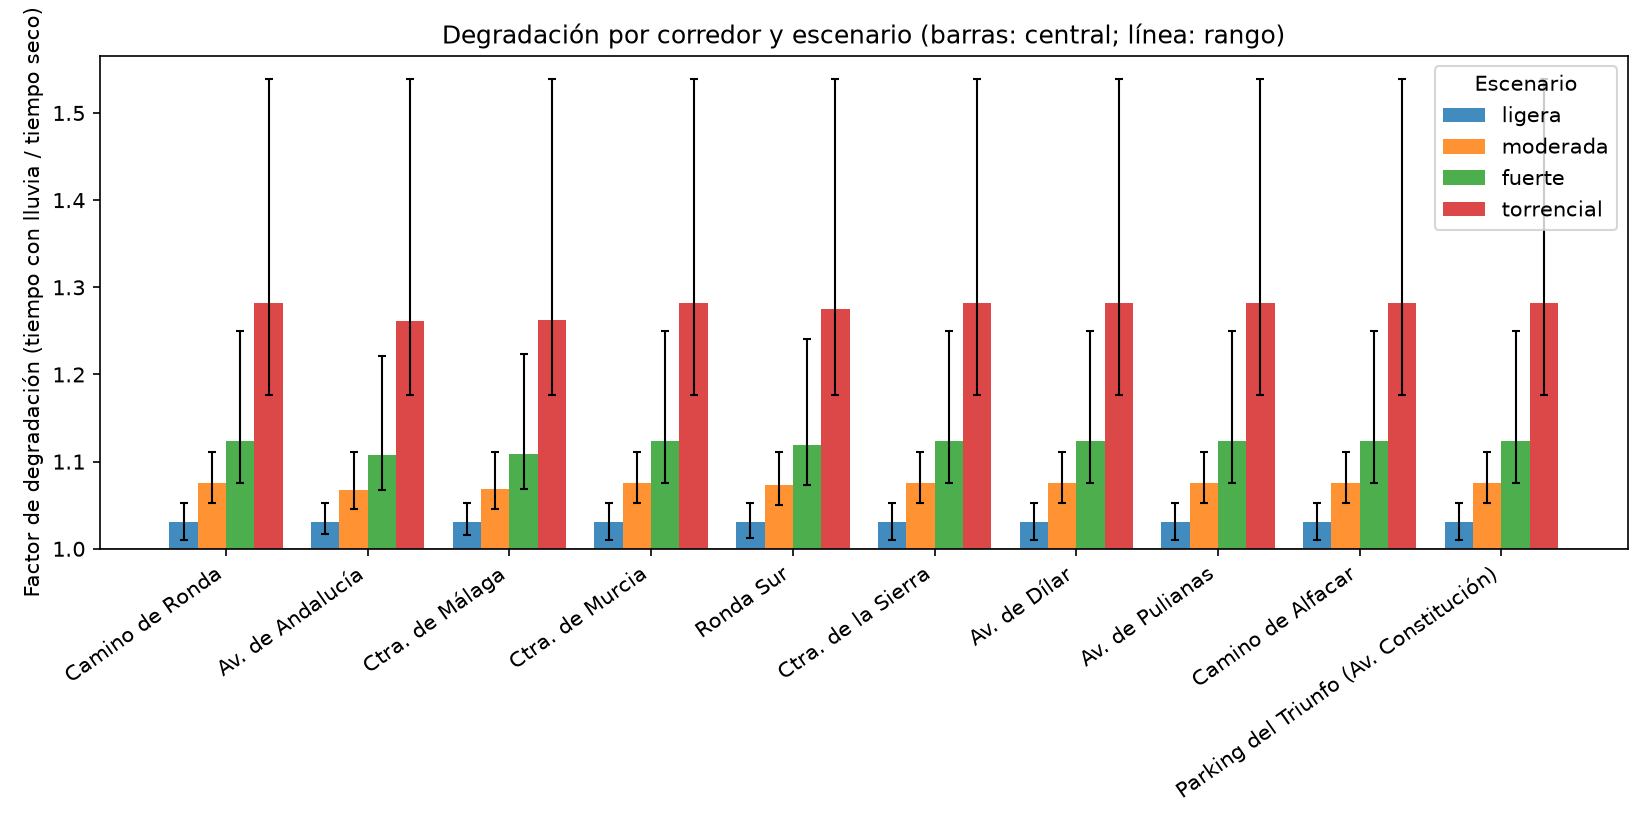

In [11]:
from IPython.display import Image
Image(filename=figura_principal(res.por_corredor, SALIDAS / "degradacion_por_corredor_escenario.png"))

### Curva de sensibilidad

Con una reducción uniforme δ el factor es ≈ 1/(1−δ); la curva muestra cuánto depende el resultado del parámetro menos seguro.

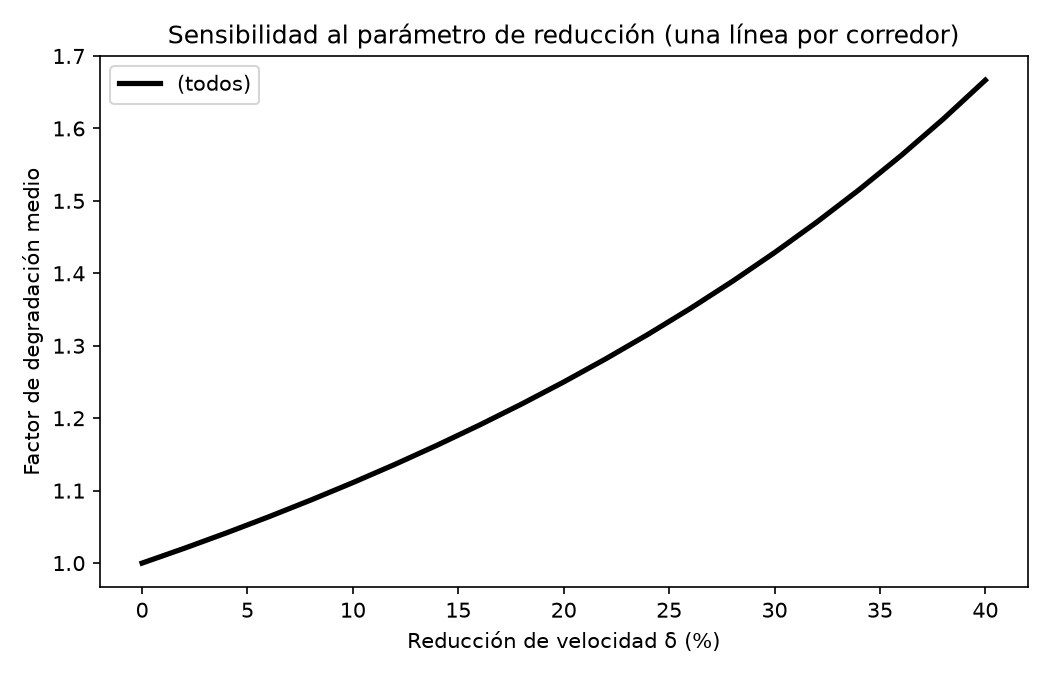

In [12]:
curva = curva_sensibilidad(G, muestra, [i / 100 for i in range(0, 41, 2)])
curva.to_csv(SALIDAS / "curva_sensibilidad.csv", index=False)
Image(filename=figura_curva(curva, SALIDAS / "curva_sensibilidad.png"))

## Visor interactivo de trayectos

Se regenera aquí mismo desde la red y la muestra verificadas, de modo que figura y datos no divergen. Es un único HTML autónomo (datos incrustados): se abre con doble clic, sin servidor. Vista canvas con leyenda por corredor; rueda para el zoom, arrastrar para mover y clic en un trayecto (lista o ruta) para acercarse a él. El botón «＋ Ruta» propone rutas nuevas (vista previa, nombre, vías con Mayús+clic, factor sobre la óptima) y «Exportar rutas» descarga un CSV que `ampliar_muestra(G, muestra, csv)` incorpora a la muestra.

In [13]:
from IPython.display import HTML

from trafico_lluvia import generar_visor

visor = generar_visor(G, muestra, SALIDAS / "visor_trayectos.html")
HTML(f'Visor regenerado: <a href="{visor.as_posix()}" target="_blank">{visor.as_posix()}</a> ({len(muestra)} trayectos)')